In [ ]:
import numpy as np
from scipy.stats import norm, gaussian_kde
import matplotlib.pyplot as plt

sigma0 = 10.0
sigma = 1.


d = 1
n = 10

mu0 = norm.rvs(scale=sigma0, size=(d,1))
mu0 = np.array([[20.]])#,15., 10., 5., 0.]])
y = norm.rvs(loc=mu0, scale=sigma, size=(d,n))

N_sample = 5000000
mus = norm.rvs(scale=sigma0, size=(N_sample,d))
zs = norm.rvs(loc=mus[:,:,None], scale=sigma, size=(N_sample,d,n))

szs = np.mean(zs, axis=2)[:,0][:,None]
phis = mus[:,0][:,None]

dists = np.linalg.norm(szs - y.mean(axis=1), axis=1)


In [2]:
import numpy as np
from typing import Callable, Tuple, Union, Optional, Dict
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

ArrayLike = Union[np.ndarray, list]

def train_logratio_mlp(
    inputs: ArrayLike,
    labels: ArrayLike,
    *,
    hidden_layer_sizes: tuple = (128, 128),
    activation: str = "relu",        # {"identity","logistic","tanh","relu"}
    alpha: float = 1e-4,             # L2
    learning_rate_init: float = 1e-3,
    max_iter: int = 200,
    early_stopping: bool = True,
    n_iter_no_change: int = 25,
    validation_fraction: float = 0.1,
    class_weight: Optional[Union[str, Dict[int, float]]] = None,  # None | "balanced" | {0:w0,1:w1}
    random_state: int = 0,
) -> Tuple[Callable[[ArrayLike], np.ndarray], Pipeline]:
    """
    Entraîne un MLP binaire fiable et renvoie:
      - logratio_fn(X_new): fonction calculant le logratio pour X_new
      - model: pipeline entraîné (StandardScaler + MLPClassifier)

    Paramètres
    ----------
    inputs : array-like, shape (n, m)
    labels : array-like, shape (n,) ou (n,1)
    hidden_layer_sizes : tuple
        Taille(s) des couches cachées, ex. (64, 64).
    activation : str
        Fonction d’activation des couches cachées.
    alpha : float
        Régularisation L2.
    learning_rate_init : float
    max_iter : int
    early_stopping : bool
        Active la validation interne du MLP.
    n_iter_no_change : int
    validation_fraction : float
    class_weight : None | "balanced" | dict
        Gestion du déséquilibre (convertie en sample_weight).
    random_state : int

    Retour
    ------
    logratio_fn : Callable
        logratio_fn(X_new) -> np.ndarray (n_new,)
        Renvoie log p(y=1|x).
    model : sklearn.Pipeline
        Pipeline StandardScaler + MLPClassifier.
    """
    X = np.asarray(inputs)
    y = np.asarray(labels).reshape(-1)

    if X.ndim != 2:
        raise ValueError("`inputs` doit avoir la forme (n, m).")
    if y.ndim != 1 or y.shape[0] != X.shape[0]:
        raise ValueError("`labels` doit être de taille (n,) ou (n,1) et correspondre à `inputs`.")
    unique = np.unique(y)
    if not np.array_equal(np.sort(unique), np.array([0, 1])):
        raise ValueError("`labels` doit contenir uniquement {0, 1}.")

    # Pipeline: standardisation puis MLP
    model = Pipeline(
        steps=[
            ("scaler", StandardScaler()),
            ("clf", MLPClassifier(
                hidden_layer_sizes=hidden_layer_sizes,
                activation=activation,
                alpha=alpha,
                learning_rate_init=learning_rate_init,
                max_iter=max_iter,
                early_stopping=early_stopping,
                n_iter_no_change=n_iter_no_change,
                validation_fraction=validation_fraction,
                random_state=random_state,
            )),
        ]
    )

    # Gestion optionnelle du déséquilibre via sample_weight transmis au step "clf"
    sw = None
    if class_weight is not None:
        if isinstance(class_weight, str):
            if class_weight != "balanced":
                raise ValueError('`class_weight` str doit être "balanced" ou None.')
            # poids proportionnels à l’inverse de la fréquence
            counts = np.bincount(y, minlength=2).astype(float)
            if counts.min() == 0:
                raise ValueError("Une des classes est absente : impossible de calculer des poids équilibrés.")
            weights = (len(y) / (2.0 * counts))
            sw = weights[y]
        elif isinstance(class_weight, dict):
            if not set(class_weight.keys()) == {0, 1}:
                raise ValueError("`class_weight` dict doit avoir les clés {0,1}.")
            sw = np.array([class_weight[int(yi)] for yi in y], dtype=float)
        else:
            raise ValueError("`class_weight` doit être None, 'balanced' ou un dict {0: w0, 1: w1}.")

    # Fit : passer les sample_weight au step 'clf' via le nom qualifié
    fit_kwargs = {}
    if sw is not None:
        fit_kwargs["clf__sample_weight"] = sw
    model.fit(X, y, **fit_kwargs)

    # Localiser l’indice de la classe positive pour predict_proba
    classes_ = model.named_steps["clf"].classes_
    try:
        idx1 = int(np.where(classes_ == 1)[0][0])
        idx0 = 1 - idx1
    except IndexError:
        raise RuntimeError("Impossible d'identifier l'indice de la classe positive (1).")

    def logratio_fn(X_new: ArrayLike) -> np.ndarray:
        Xn = np.asarray(X_new)
        if Xn.ndim == 1:
            Xn = Xn.reshape(1, -1)
        if Xn.ndim != 2 or Xn.shape[1] != X.shape[1]:
            raise ValueError(f"`X_new` doit avoir {X.shape[1]} colonnes (features).")
        proba = model.predict_proba(Xn)  # shape (n_new, 2), softmax du MLP
        p1 = proba[:, idx1]
        p0 = proba[:, idx0]
        eps = 1e-12
        denom = np.clip(p0 + p1, eps, 1.0)  # =1 mais on garde votre forme
        return np.log(np.clip(p1, eps, 1.0)) - np.log(denom)

    return logratio_fn, model

# --- Exemple d'utilisation ---
# X = np.random.randn(200, 10)
# y = (X[:, 0] - 0.5*X[:, 1] + 0.2*np.random.randn(200) > 0).astype(int)
# logratio, model = train_logratio_mlp(X, y, hidden_layer_sizes=(128,64), class_weight="balanced")
# x_new = np.random.randn(5, 10)
# print(logratio(x_new))  # -> array de log p(y=1|x)

def logratio_fn(phis, z):
    m = phis.shape[0]
    sz = np.mean(z, axis=1)
    
    szs = np.repeat(sz, m, axis=0)
    print(phis.shape, szs.shape)
    x_new = np.append(phis, szs[:,None], axis=1)
    print(x_new.shape)
    return lr(x_new)


In [3]:
alphas = [1.0, 0.1, 0.01, 0.001]
models = []
log_rs = []
kdes = []
for alpha in alphas:
    epsilon = np.quantile(dists, alpha)

    accept = dists <= epsilon
    n_acc = accept.sum()
    phis_acc = phis[accept]
    szs_acc = szs[accept]

    inputs1 = np.append(phis_acc, szs_acc, axis=1)
    labels1 = np.ones((n_acc,1))

    perm = np.random.permutation(n_acc)
    inputs0 = np.append(phis_acc[perm], szs_acc, axis=1)
    labels0 = np.zeros((n_acc,1))

    inputs = np.concatenate([inputs1, inputs0], axis=0)
    labels = np.concatenate([labels1, labels0], axis=0).astype(int)
    print(f"Training... on {inputs.shape[0]} samples")
    lr, model = train_logratio_mlp(inputs, labels, hidden_layer_sizes=(128,128,128))
    models.append(model)
    log_rs.append(lr)
    kdes.append(gaussian_kde(phis_acc.flatten()[:min(100000, n_acc)]))
    print(f"alpha={alpha}, epsilon={epsilon}, n_acc={n_acc}")
    
    

Training... on 10000000 samples
alpha=1.0, epsilon=72.23445333019893, n_acc=5000000
Training... on 1000000 samples
alpha=0.1, epsilon=7.211663544595903, n_acc=500000
Training... on 100000 samples
alpha=0.01, epsilon=0.8940208304047752, n_acc=50000
Training... on 10000 samples
alpha=0.001, epsilon=0.08809396666158212, n_acc=5000


In [4]:

def nre_posterior_pdf(phis, z):
    log_r = logratio_fn(phis, z)
    log_pdf = norm.logpdf(phis, scale=sigma0).reshape(-1)+log_r.reshape(-1)
    return np.exp(log_pdf)

def abc_nre_posterior_pdf(phis, z, kde):
    log_r = logratio_fn(phis, z)
    pdf = np.exp(log_r)*kde(phis[:,0])
    return pdf / np.trapz(pdf, phis[:,0])


def norm_nre_posterior_pdf(phis, z):
    pdf = nre_posterior_pdf(phis, z)
    return pdf / np.trapz(pdf, phis[:,0])

def norm_abc_nre_posterior_pdf(phis, z, kde):
    pdf = abc_nre_posterior_pdf(phis, z, kde)
    return pdf / np.trapz(pdf, phis[:,0])

def true_posterior_pdf(phis, z):
    sigma_post = 1 / np.sqrt(1/sigma0**2 + n/sigma**2)
    mu_post = sigma_post**2 * np.sum(z, axis=1) / sigma**2
    return norm.pdf(phis, loc=mu_post, scale=sigma_post).reshape(-1)



(10000, 1) (10000,)
(10000, 2)
(10000, 1) (10000,)
(10000, 2)


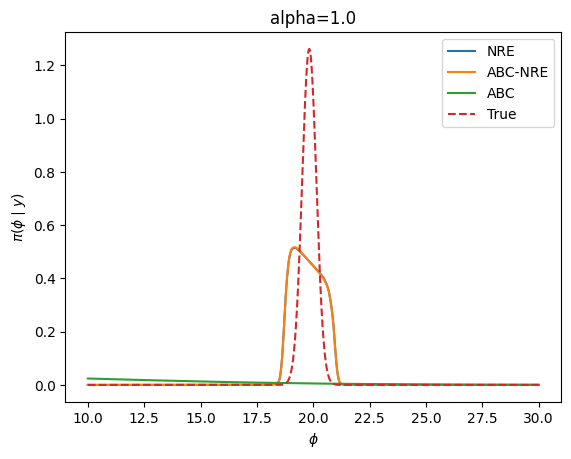

(10000, 1) (10000,)
(10000, 2)
(10000, 1) (10000,)
(10000, 2)


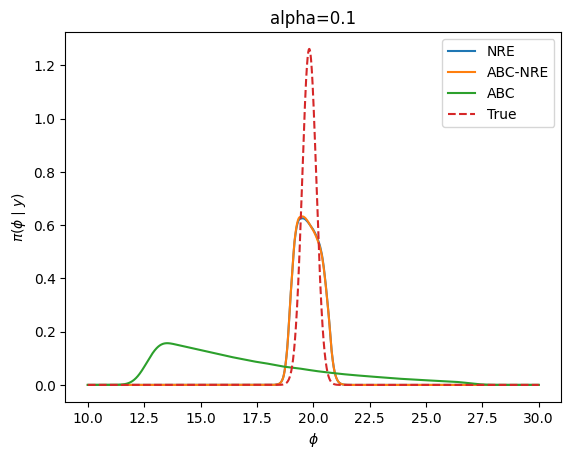

(10000, 1) (10000,)
(10000, 2)
(10000, 1) (10000,)
(10000, 2)


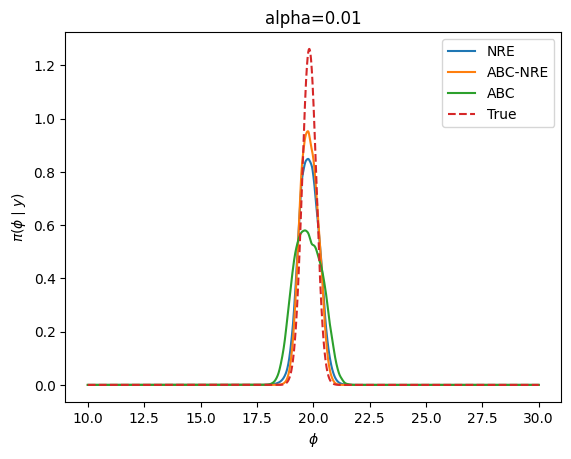

(10000, 1) (10000,)
(10000, 2)
(10000, 1) (10000,)
(10000, 2)


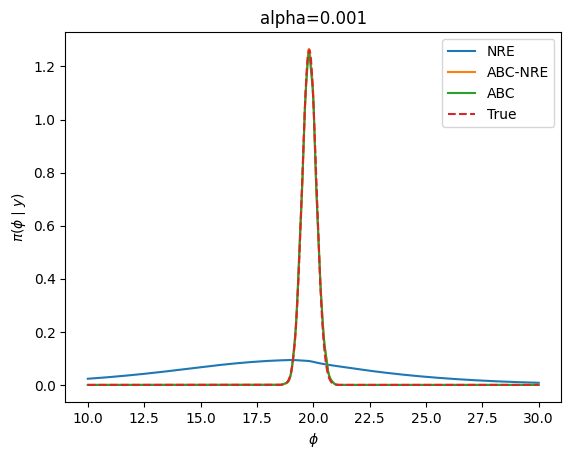

In [7]:
for i, alpha in enumerate(alphas):
    phis = np.linspace(10, 30, 10000)[:,None]
    lr = log_rs[i]
    nre_post = norm_nre_posterior_pdf(phis, y)
    abc_nre_post = norm_abc_nre_posterior_pdf(phis, y, kdes[i])
    abc_post = kdes[i](phis[:,0])
    true_post = true_posterior_pdf(phis, y)
    plt.plot(phis, nre_post, label="NRE")
    plt.plot(phis, abc_nre_post, label="ABC-NRE")
    plt.plot(phis, abc_post, label="ABC")
    plt.plot(phis, true_post, linestyle='--', label="True")
    plt.xlabel("$\phi$")
    plt.ylabel("$\pi(\phi \mid y)$")
    plt.title(f"alpha={alpha}")
    plt.legend()
    plt.show()

